# 06 · Resultado de las técnicas de clase
    **Objetivo.** Elegir una partición con suficiente detalle para explorar columnas,
    tuberías, piso, techo, vigas y equipos, sin confundir silhouette alto con utilidad.
    Volvemos a ajustar y propagamos a los 1 647 021 puntos conservando normales.
    Los clusters pueden mezclar estructuras: no tenemos ground truth.

**Nota de ejecución.** Celdas ejecutadas en orden con IPython dentro de `.venv`, porque nbconvert no pudo abrir los sockets del kernel en este sandbox. El usuario había verificado la versión previa con nbconvert fuera de esta restricción. Logs de esta revisión en `outputs/logs/`; auxiliares en `outputs/cache/`.

In [1]:
import os, sys, json, time, importlib.util
from pathlib import Path
sys.path.insert(0, "../../src")
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, voxel_ids, build_features
from pcseg.propagate import propagate_labels
from pcseg.metrics import cluster_summary, silhouette_sample, davies_bouldin, stability_ari
# Mostramos los PNG generados sin abrir ventanas gráficas.
plt.switch_backend("module://matplotlib_inline.backend_inline")
# Evitamos que muchos threads hagan más lento un problema pequeño.
thread_limit = threadpool_limits(limits=2)
OUT = Path('../../outputs'); FIG = OUT / 'figs'; ENT = Path('../../entregable'); ENT.mkdir(exist_ok=True)
CACHE = OUT / 'cache'; LOGS = OUT / 'logs'
for folder in (OUT, FIG, CACHE, LOGS): folder.mkdir(exist_ok=True)
(LOGS / 'clase_labels').mkdir(exist_ok=True)
START = time.perf_counter()
SEED = 0
print('Python:', sys.executable, sys.version.split()[0])
assert Path(sys.prefix).resolve() == Path('../../.venv').resolve(), 'Ejecutar con .venv'

Python: /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


### Cómo vamos a dibujar
Usamos una función local de matplotlib: puntos de tamaño 2–2.2 y alpha=0.6. La paleta prioriza colores contrastantes y es la misma en figuras y PLY. Esto cambia la presentación, no el clustering.

In [2]:
# Reordenamos tab20: primero los tonos fuertes; misma paleta en PNG y PLY.
SEGMENT_PALETTE = (np.array(plt.get_cmap('tab20').colors)[
    np.r_[np.arange(0,20,2), np.arange(1,20,2)]] * 255).astype(np.uint8)
def segment_rgb(labels):
    return labels_to_rgb(labels, palette=SEGMENT_PALETTE)

def scatter_views(points, values, path, title, max_points=40000, seed=0):
    # Variante local: puntos visibles y alpha=0.6, sin modificar pcseg.viz.
    if len(points) > max_points:
        idx = np.random.default_rng(seed).choice(len(points), max_points, replace=False)
        points, values = points[idx], values[idx]
    colors = (segment_rgb(values) if values.ndim == 1 else values) / 255.
    fig = plt.figure(figsize=(18,6))
    for j, (axis, label) in enumerate(((1,'y'),(2,'z')), start=1):
        ax = fig.add_subplot(1,3,j)
        ax.scatter(points[:,0],points[:,axis],c=colors,s=2.2,alpha=.6,linewidths=0)
        ax.set(xlabel='x',ylabel=label,title='Superior' if j==1 else 'Lateral',aspect='equal')
    ax = fig.add_subplot(1,3,3,projection='3d')
    ax.scatter(*points.T,c=colors,s=2,alpha=.6,linewidths=0)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D')
    ax.set_box_aspect(np.maximum(np.ptp(points,axis=0),1e-9))
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path,dpi=150); plt.close(fig)

### Recuperamos la misma muestra
No volvemos a sortear puntos: cargamos los índices guardados en 01.

In [3]:
cloud = read_ply('../../data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
sample_idx = np.load(OUT / 'sample_idx.npy')
assert len(np.unique(sample_idx)) == len(sample_idx)
xyz, rgb, normals = (cloud[key][sample_idx] for key in ('xyz', 'rgb', 'normals'))
print('Muestra común:', len(xyz), 'de', len(cloud['xyz']))

Muestra común: 93903 de 1647021


### Antes de comparar: fijemos la regla
Trabajamos siempre con los índices voxel de 01. `rgb` pasa a CIE Lab dentro de
`build_features`: aquí el nombre del conjunto indica el dato de origen.
`height = z - percentil_1(z)` repite la información de z y le da más peso a la altura.

Calculamos silhouette en 1200 puntos (semilla 0) y Davies-Bouldin sin ruido.
Silhouette mayor y DB menor son deseables, pero dependen de la distancia elegida.
Por eso guardamos además `silhouette_comun` y `DB_comun`, siempre sobre las mismas
features completas estandarizadas. No hay ground truth: ninguna métrica demuestra
que los grupos sean objetos físicos. ARI compara corridas, no exactitud.
Los segundos del CSV incluyen ajuste, predicción y estabilidad, y excluyen evaluación y figuras.

In [4]:
FEATURES = {
    'xyz': {},
    'xyz+rgb': {'use_rgb': True},
    'xyz+normales': {'use_normals': True},
    'xyz+rgb+normales+height': {'use_rgb': True, 'use_normals': True, 'use_height': True},
}
def features(name, scaled=True):
    return build_features(xyz, rgb, normals, standardize=scaled, **FEATURES[name])
# Evaluación común: igual distancia y mismas filas para comparar métodos/features.
EVAL = features('xyz+rgb+normales+height')

In [5]:
NB = '06'

rows = []
def record(method, feature, scaled, params, X, labels, seconds, ari, ari_std=0., **extra):
    summary = cluster_summary(labels)
    own_sil = silhouette_sample(X, labels, n=1200, seed=0)
    own_db = davies_bouldin(X, labels)
    common_sil = silhouette_sample(EVAL, labels, n=1200, seed=0)
    common_db = davies_bouldin(EVAL, labels)
    counts = np.array(list(summary['sizes'].values()), dtype=int)
    row_id = f'{NB}_{len(rows):03d}'
    row = dict(id=row_id, metodo=method, features=feature, estandarizado=bool(scaled),
        parametros=json.dumps(params, sort_keys=True), n_fit=extra.get("n_ajuste", len(X)), n_evaluacion=len(X),
        n_clusters=summary['n_clusters'], ruido=summary['noise_frac'],
        silhouette=own_sil, DB=own_db, ARI=ari, ARI_std=ari_std,
        silhouette_comun=common_sil, DB_comun=common_db, segundos=seconds,
        min_cluster_frac=float(counts.min()/len(labels)) if len(counts) else 0.,
        max_cluster_frac=float(counts.max()/len(labels)) if len(counts) else 0., **extra)
    rows.append(row)
    np.save(LOGS / 'clase_labels' / f'{row_id}.npy', labels.astype(np.int32))
    return row

def table():
    df = pd.DataFrame(rows)
    df.to_csv(OUT / f'metricas_{NB}.csv', index=False)
    return df

def view(labels, suffix, title):
    path = FIG / f'{NB}_{suffix}.png'
    scatter_views(xyz, labels, path, title, max_points=30000, seed=0)
    display(Image(filename=str(path)))

def finish(payload):
    payload['segundos_notebook'] = time.perf_counter() - START
    (CACHE / f'clase_resumen_{NB}.json').write_text(json.dumps(payload, indent=2))
    print(payload)

### La selección ahora responde al objetivo
    La primera regla permitía K=2 y acabó separando una franja superior del resto.
    Ese resultado podía tener silhouette alto y seguir siendo demasiado grueso.
    Conservamos todas las pruebas, incluidas K pequeños, para medir ese hallazgo.

    Exigimos **6–15 clusters, ruido ≤30% y ningún cluster >60% de la muestra**.
    Necesitamos silhouette común, DB común y ARI finitos para calcular el ranking.
    No añadimos un umbral mínimo de ARI ni de tamaño de cada cluster. BIC sigue
    siendo el diagnóstico de GMM en 04; aquí comparamos todas las configuraciones
    que cumplen estos límites con el mismo ranking, independientemente del método.

    Si no hay candidatos, relajamos primero el tamaño máximo a **70%**, conservando
    ruido ≤30%; solo si aún no hay candidatos permitimos **ruido ≤50%**, manteniendo
    el máximo de 70%. Nunca relajamos el rango 6–15. Registramos la etapa aplicada.

    Elegimos la media de tres ranks con igual peso: `silhouette_comun` descendente,
    `DB_comun` ascendente y `ARI` descendente. Desempatamos por silhouette común e ID.
    Las fracciones del filtro corresponden a la muestra voxel; también revisaremos
    tamaños en la nube completa tras propagar. ARI de métodos deterministas sigue
    siendo una limitación: 1 no demuestra estabilidad ante remuestreo.

In [6]:
results = pd.concat([pd.read_csv(OUT/f'metricas_{n}.csv') for n in ('02','03','04')],ignore_index=True)
finite = np.isfinite(results[['silhouette_comun','DB_comun','ARI']]).all(axis=1)
base_mask = finite & results.n_clusters.between(6,15)
levels = [('estricto',.6,.3), ('max_cluster_70',.7,.3), ('ruido_50',.7,.5)]
selection_steps = []
for selection_stage, max_frac, max_noise in levels:
    mask = base_mask & (results.max_cluster_frac<=max_frac) & (results.ruido<=max_noise)
    selection_steps.append(dict(etapa=selection_stage,max_cluster_frac=max_frac,
                                ruido=max_noise,candidatos=int(mask.sum())))
    if mask.any(): break
assert mask.any(), 'No hay candidatos ni tras las dos relajaciones: revisar experimentos'
results['elegible_estricto'] = base_mask & (results.max_cluster_frac<=.6) & (results.ruido<=.3)
results['elegible'] = mask
results['etapa_seleccion'] = selection_stage
results['limite_max_cluster_frac'] = max_frac
results['limite_ruido'] = max_noise
eligible = results[mask].copy()
eligible['rank_medio'] = (eligible.silhouette_comun.rank(ascending=False)
    + eligible.DB_comun.rank(ascending=True) + eligible.ARI.rank(ascending=False))/3
results['rank_medio'] = eligible.rank_medio
best = eligible.sort_values(['rank_medio','silhouette_comun','id'],ascending=[True,False,True]).iloc[0]
results['seleccionada'] = results.id.eq(best.id)
results.to_csv(ENT/'clase_metricas.csv',index=False)
display(pd.DataFrame(selection_steps))
display(eligible.sort_values(['rank_medio','silhouette_comun','id'],ascending=[True,False,True])[
    ['id','metodo','features','parametros','n_clusters','ruido','max_cluster_frac',
     'silhouette_comun','DB_comun','ARI','rank_medio']].head(10))
print('Elegido:',best.id,'etapa:',selection_stage,'candidatos:',len(eligible))

,etapa,max_cluster_frac,ruido,candidatos
0,estricto,0.6,0.3,68


,id,metodo,features,parametros,n_clusters,ruido,max_cluster_frac,silhouette_comun,DB_comun,ARI,rank_medio
86,02_086,kmeans,xyz+rgb+normales+height,"{""max_iter"": 200, ""n_clusters"": 11, ""n_init"": 3}",11,0.0,0.188482,0.213259,1.510333,0.952452,8.333333
61,02_061,kmeans,xyz+normales,"{""max_iter"": 200, ""n_clusters"": 8, ""n_init"": 3}",8,0.0,0.162583,0.166840,1.815021,0.998622,11.666667
83,02_083,kmeans,xyz+rgb+normales+height,"{""max_iter"": 200, ""n_clusters"": 8, ""n_init"": 3}",8,0.0,0.218641,0.198018,1.562265,0.926762,12.666667
104,04_006,agglomerative,xyz,"{""linkage"": ""complete"", ""n_clusters"": 6}",6,0.0,0.288723,0.112747,2.515391,1.000000,17.166667
64,02_064,kmeans,xyz+normales,"{""max_iter"": 200, ""n_clusters"": 11, ""n_init"": 3}",11,0.0,0.129495,0.164259,1.781247,0.908335,17.333333
39,02_039,kmeans,xyz+rgb,"{""max_iter"": 200, ""n_clusters"": 8, ""n_init"": 3}",8,0.0,0.222762,0.186865,1.810004,0.839215,18.333333
38,02_038,kmeans,xyz+rgb,"{""max_iter"": 200, ""n_clusters"": 7, ""n_init"": 3}",7,0.0,0.236127,0.177950,1.916055,0.895440,18.666667
63,02_063,kmeans,xyz+normales,"{""max_iter"": 200, ""n_clusters"": 10, ""n_init"": 3}",10,0.0,0.147120,0.162093,1.775753,0.852273,19.000000
60,02_060,kmeans,xyz+normales,"{""max_iter"": 200, ""n_clusters"": 7, ""n_init"": 3}",7,0.0,0.169494,0.164988,1.927290,0.875572,21.000000
85,02_085,kmeans,xyz+rgb+normales+height,"{""max_iter"": 200, ""n_clusters"": 10, ""n_init"": 3}",10,0.0,0.192220,0.210343,1.532920,0.732065,21.333333


Elegido: 02_086 etapa: estricto candidatos: 68


### Comparemos con los K pequeños que parecían mejores
    La tabla contrasta la configuración nueva con el mayor silhouette común de K=2
    y con complete K=2 (la elección anterior). Si el número mejora al agrupar casi
    todo en dos colores, todavía no satisface el detalle que buscamos. Esta es una
    limitación del criterio, no una razón para ocultar esos resultados.

In [7]:
k2 = results[results.n_clusters.eq(2)].sort_values('silhouette_comun',ascending=False).iloc[0]
previous = results[(results.metodo=='agglomerative') & results.n_clusters.eq(2)
                   & results.parametros.str.contains('"linkage": "complete"')].iloc[0]
comparison = pd.DataFrame([k2,previous,best])
display(comparison[['id','metodo','n_clusters','silhouette_comun','DB_comun','ARI','max_cluster_frac']])
comparison.to_csv(CACHE/'clase_comparacion_k2.csv',index=False)

,id,metodo,n_clusters,silhouette_comun,DB_comun,ARI,max_cluster_frac
77,02_077,kmeans,2,0.261461,1.539746,0.999531,0.710723
102,04_004,agglomerative,2,0.246493,1.507834,1.000000,0.740456
86,02_086,kmeans,11,0.213259,1.510333,0.952452,0.188482


### Repetimos el ajuste elegido
    Usamos los mismos hiperparámetros y semilla 0. Si corresponde recuperamos las
    submuestras de jerarquía o GMM. Jerarquía no tiene predict: primero propagamos
    de sus representantes a la muestra voxel. ARI=1 contra las etiquetas guardadas
    comprueba que el reajuste reprodujo esa corrida.

In [8]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
params = json.loads(best.parametros)
X = features(best.features, bool(best.estandarizado))
tick = time.perf_counter()
if best.metodo=='kmeans':
    labels = KMeans(**params,random_state=0).fit_predict(X)
elif best.metodo=='dbscan':
    labels = DBSCAN(**params,n_jobs=2).fit_predict(X)
elif best.metodo=='gmm':
    idx = np.load(CACHE/'clase_gmm_idx.npy')
    labels = GaussianMixture(**params,random_state=0).fit(X[idx]).predict(X)
elif best.metodo=='agglomerative':
    idx = np.load(CACHE/'clase_jerarquico_idx.npy')
    lab = AgglomerativeClustering(**params).fit_predict(X[idx])
    labels = propagate_labels(xyz[idx],lab,xyz)
else:
    raise ValueError(best.metodo)
refit_seconds = time.perf_counter()-tick
saved = np.load(LOGS/'clase_labels'/f'{best.id}.npy')
refit_ari = float(adjusted_rand_score(labels,saved))
assert refit_ari == 1.0
assert 6 <= cluster_summary(labels)['n_clusters'] <= 15
print('Reajuste (s):',refit_seconds,'ARI respecto a la corrida guardada:',refit_ari)

Reajuste (s): 0.385803239998495 ARI respecto a la corrida guardada: 1.0


### Etiquetas y colores para todos los puntos
    El vecino espacial más cercano (`k=1`) lleva las etiquetas a la nube completa.
    Esta aproximación puede desplazar fronteras. Conservamos orden, coordenadas
    y normales, y usamos la misma paleta contrastante del notebook. El ruido es gris.
    Releemos el PLY para verificar conservación y al menos seis colores distintos.

In [9]:
tick = time.perf_counter()
labels_all = propagate_labels(xyz,labels,cloud['xyz'],k=1)
np.save(CACHE/'clase_labels_full.npy',labels_all.astype(np.int32))
write_ply(ENT/'clase_segmentos.ply',cloud['xyz'],segment_rgb(labels_all),cloud['normals'])
propagate_seconds = time.perf_counter()-tick
check = read_ply(ENT/'clase_segmentos.ply')
assert np.array_equal(check['xyz'],cloud['xyz'])
assert np.array_equal(check['normals'],cloud['normals'])
assert np.array_equal(check['rgb'],segment_rgb(labels_all))
assert check['rgb'].dtype == np.uint8
assert len(labels_all)==1647021
assert np.array_equal(labels_all[sample_idx],labels)
color_count = len(np.unique(check['rgb'],axis=0))
assert color_count >= 6
assert cluster_summary(labels_all)['n_clusters'] == int(best.n_clusters)
print('PLY verificado:',len(labels_all),'puntos, mismas coordenadas y normales;',color_count,'colores')
print('Muestra:',cluster_summary(labels)); print('Nube completa:',cluster_summary(labels_all))

PLY verificado: 1647021 puntos, mismas coordenadas y normales; 11 colores
Muestra: {'n_clusters': 11, 'n_noise': 0, 'noise_frac': 0.0, 'sizes': {0: 17699, 1: 10325, 2: 8823, 3: 7966, 4: 3589, 5: 9185, 6: 7885, 7: 9053, 8: 10313, 9: 2158, 10: 6907}}
Nube completa: {'n_clusters': 11, 'n_noise': 0, 'noise_frac': 0.0, 'sizes': {0: 335493, 1: 195988, 2: 182305, 3: 134071, 4: 66997, 5: 133665, 6: 117767, 7: 127128, 8: 199141, 9: 36171, 10: 118295}}


### Revisemos el conjunto antes de separar los paneles
    La figura de la muestra y la de la nube completa usan puntos más visibles con
    alpha=0.6. Los colores identifican clusters; no implican categorías semánticas.

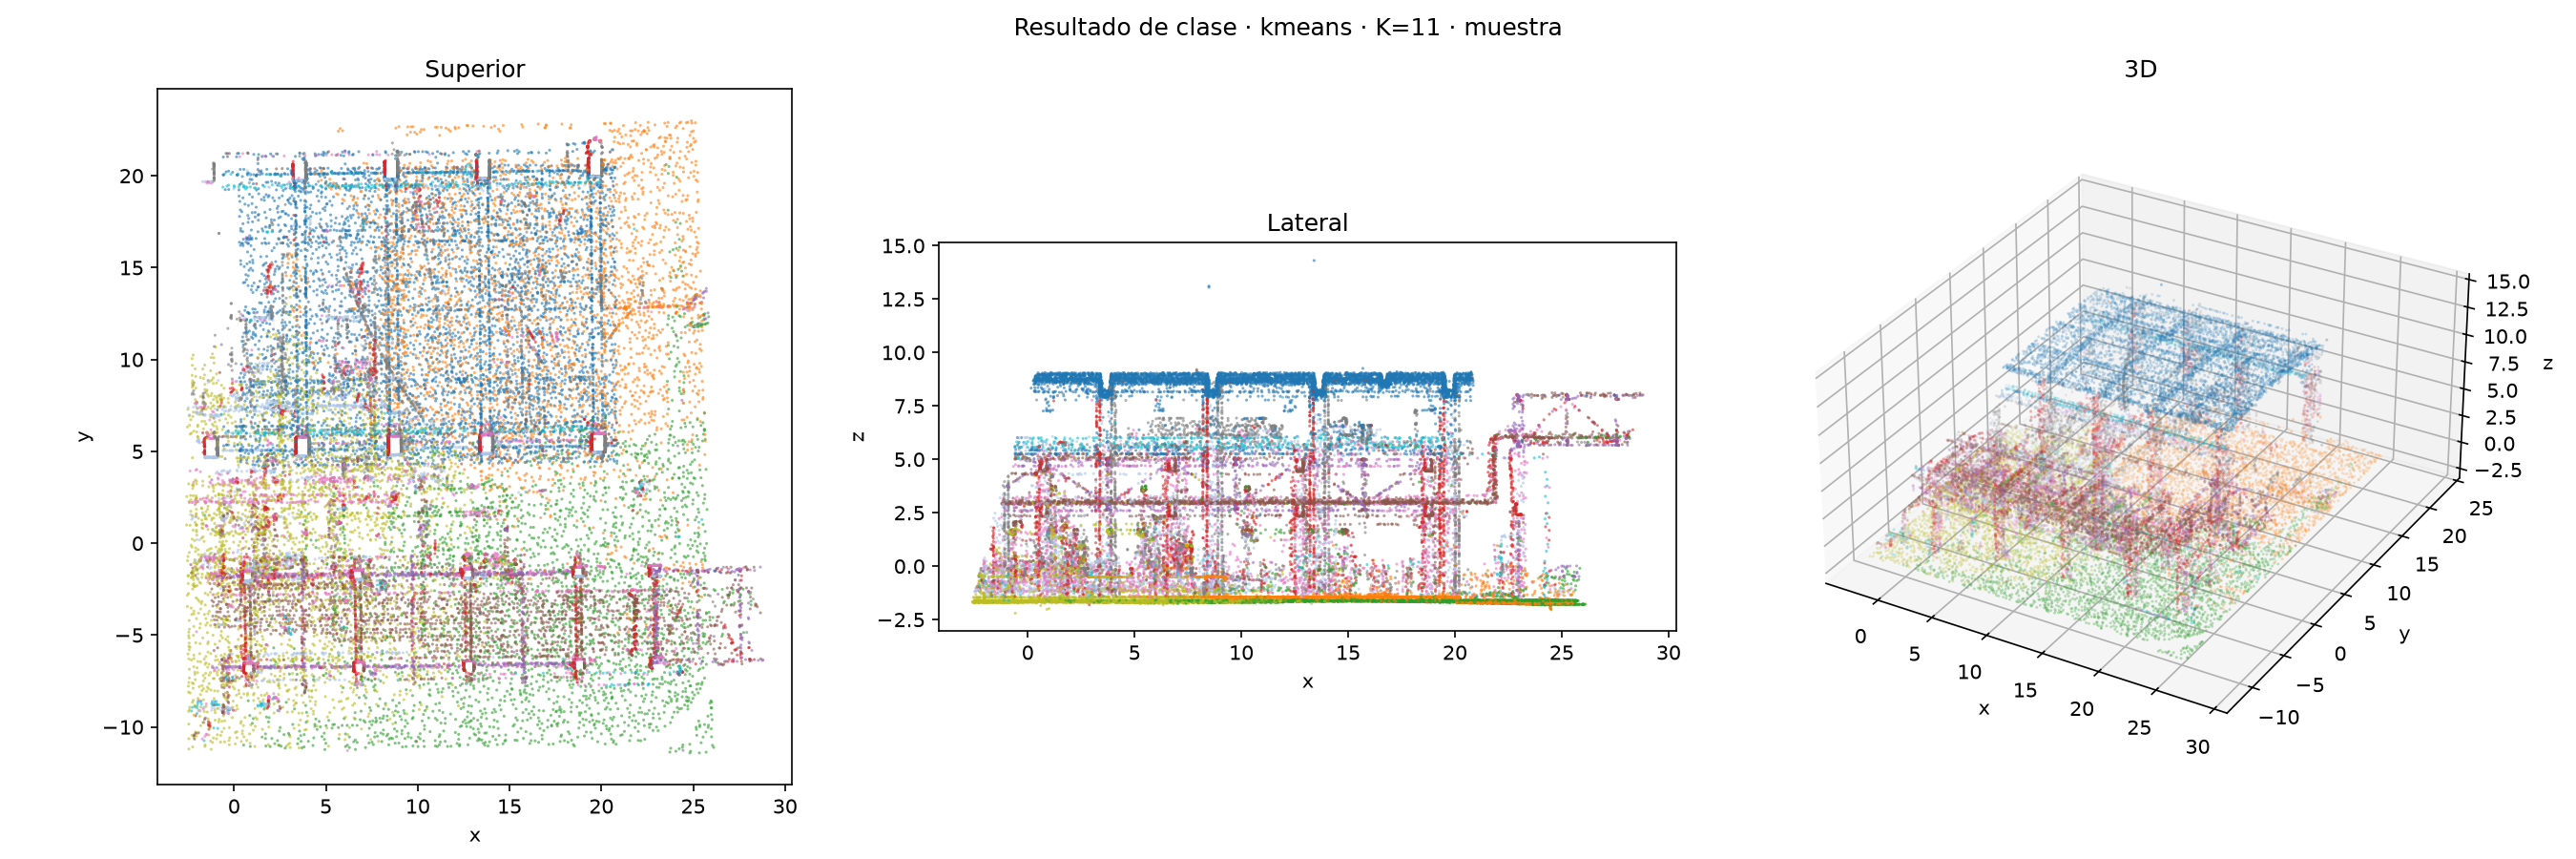

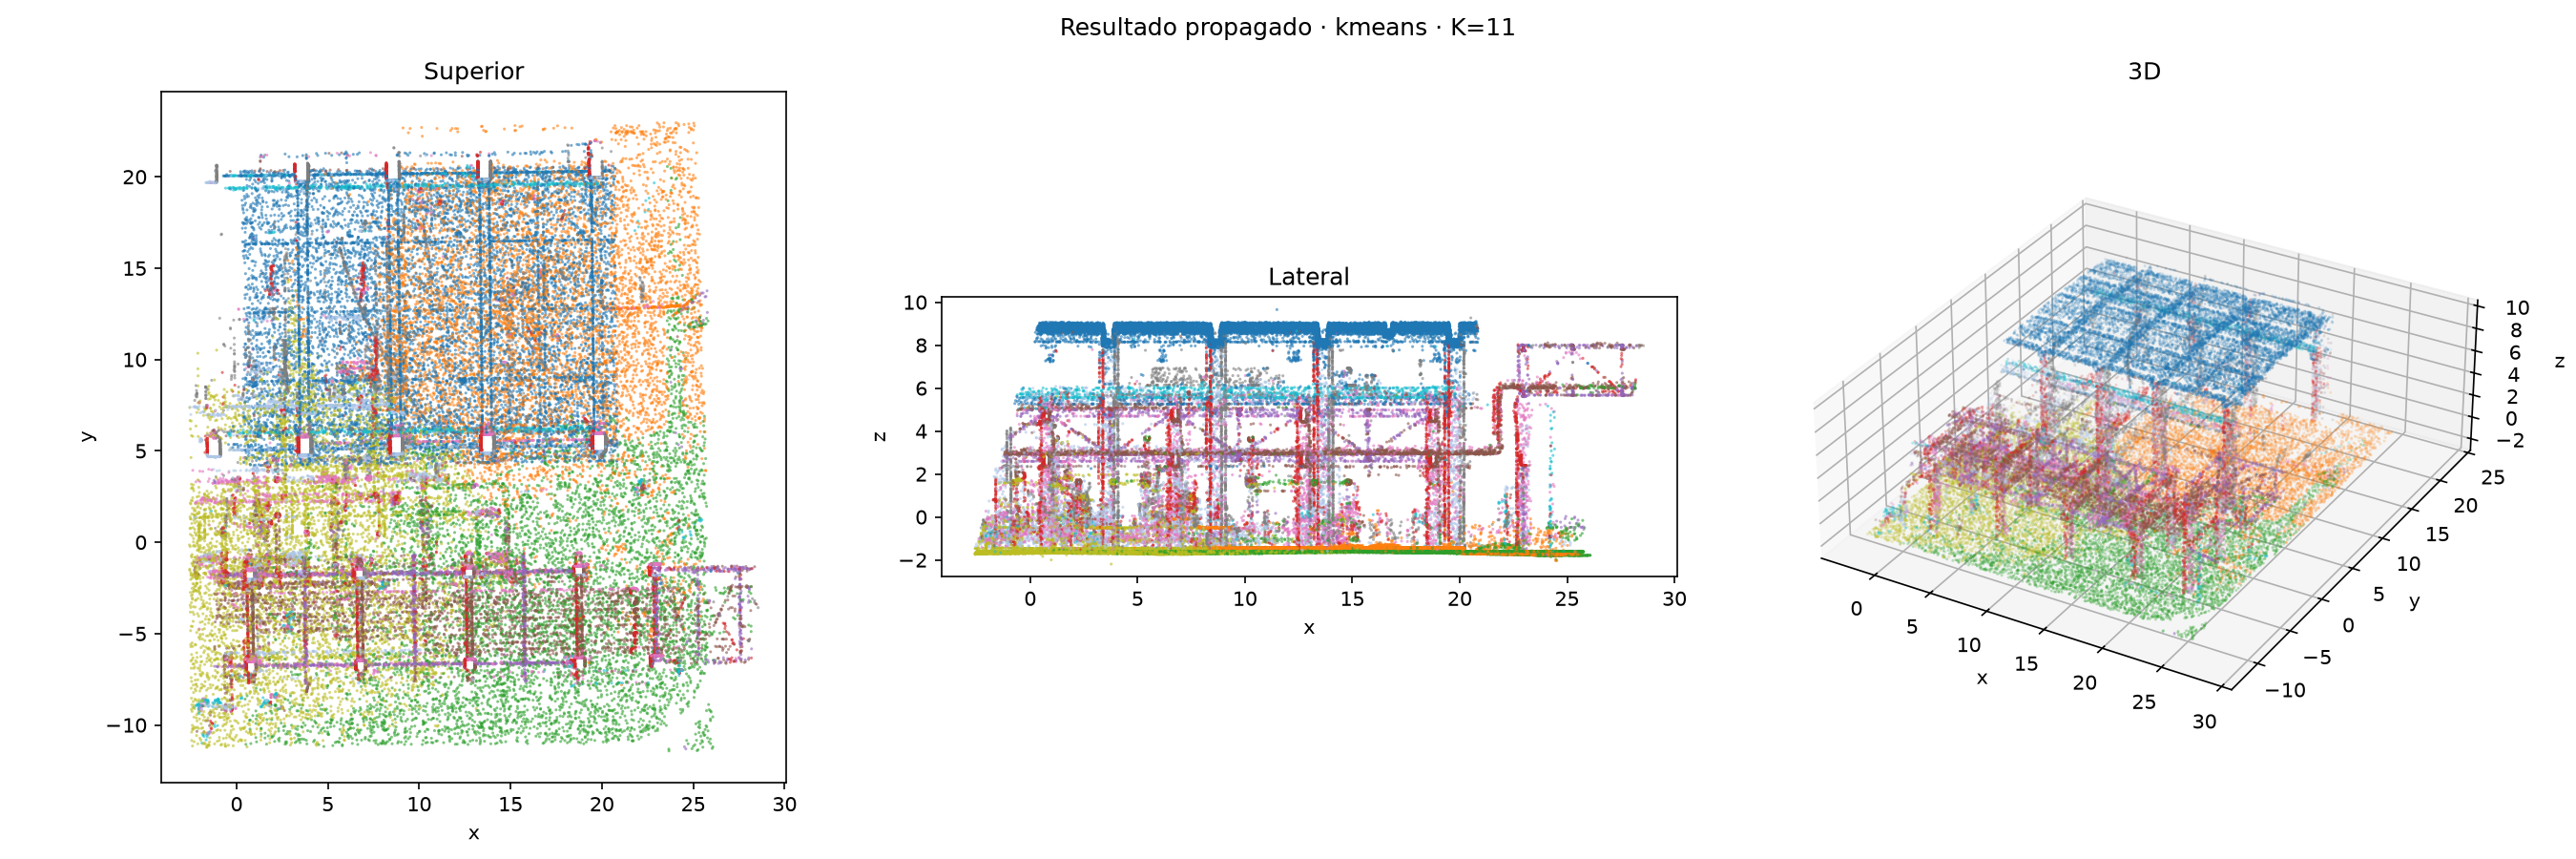

In [10]:
view(labels,'muestra',f'Resultado de clase · {best.metodo} · K={int(best.n_clusters)} · muestra')
path = FIG/'06_completo.png'
scatter_views(cloud['xyz'],labels_all,path,f'Resultado propagado · {best.metodo} · K={int(best.n_clusters)}',max_points=60000,seed=0)
display(Image(filename=str(path)))

### Ahora, cada cluster por separado: ¿qué parte captura?
    Cada panel lateral mantiene los mismos ejes x–z y muestra un solo cluster sobre
    una referencia gris tenue de la fábrica. El título indica el tamaño **completo**,
    aunque limitemos el dibujo a 12 mil puntos por cluster. La proyección superpone
    posiciones con distinto y: usaremos también los rangos y las vistas 3D para leerla.
    No asignamos nombres de objetos a partir del color: la interpretación visual
    posterior es tentativa y debe reconocer cuando un grupo mezcla estructuras.

In [11]:
cluster_ids = np.unique(labels_all[labels_all>=0])
cluster_rows = []
for label in cluster_ids:
    keep = labels_all==label
    pts = cloud['xyz'][keep]
    row = dict(cluster=int(label),n_puntos=int(keep.sum()),fraccion=float(keep.mean()),
               nz_mediana=float(np.median(cloud['normals'][keep,2])))
    for j,axis in enumerate('xyz'):
        for q,value in zip(('05','50','95'),np.quantile(pts[:,j],[.05,.5,.95])):
            row[f'{axis}_q{q}'] = float(value)
    cluster_rows.append(row)
cluster_table = pd.DataFrame(cluster_rows)
cluster_table.to_csv(CACHE/'clase_clusters.csv',index=False)
display(cluster_table)

,cluster,n_puntos,fraccion,nz_mediana,x_q05,x_q50,x_q95,y_q05,y_q50,y_q95,z_q05,z_q50,z_q95
0,0,335493,0.203697,-0.949861,1.505247,10.856909,19.618225,5.097685,12.642026,20.156136,5.637429,8.680657,9.011111
1,1,195988,0.118995,0.999913,8.672529,16.522726,24.496791,3.465446,12.057158,20.156336,-1.745500,-1.448499,-0.503096
2,2,182305,0.110688,0.999884,5.860820,17.102697,24.939044,-10.390748,-3.189169,5.587912,-1.755641,-1.613098,1.194706
3,3,134071,0.081402,-0.002979,0.399031,8.755561,22.724350,-6.765866,-0.938601,20.451520,-0.941677,2.344350,6.583773
4,4,66997,0.040678,-0.025421,0.984828,11.424130,26.502288,-6.749633,-2.216510,1.218017,-0.281286,3.695746,7.845801
5,5,133665,0.081156,-0.953957,0.286283,11.603496,24.104613,-6.731756,-3.561149,5.356738,0.639815,2.981773,6.057417
6,6,117767,0.071503,-0.003984,-0.741475,7.487971,22.858418,-6.686159,-1.263836,9.604681,-1.157580,0.732413,5.386695
7,7,127128,0.077187,0.001283,-0.693294,8.252416,20.194342,-1.858715,7.681195,20.488192,-1.031901,1.908704,7.591237
8,8,199141,0.120910,0.999339,-1.781499,3.717330,11.424054,-8.853376,-0.472453,7.745606,-1.699788,-1.608126,1.527801
9,9,36171,0.021961,-0.032481,-0.594386,9.584189,23.055641,-8.696994,6.206347,20.086127,-1.338951,5.576238,6.013611


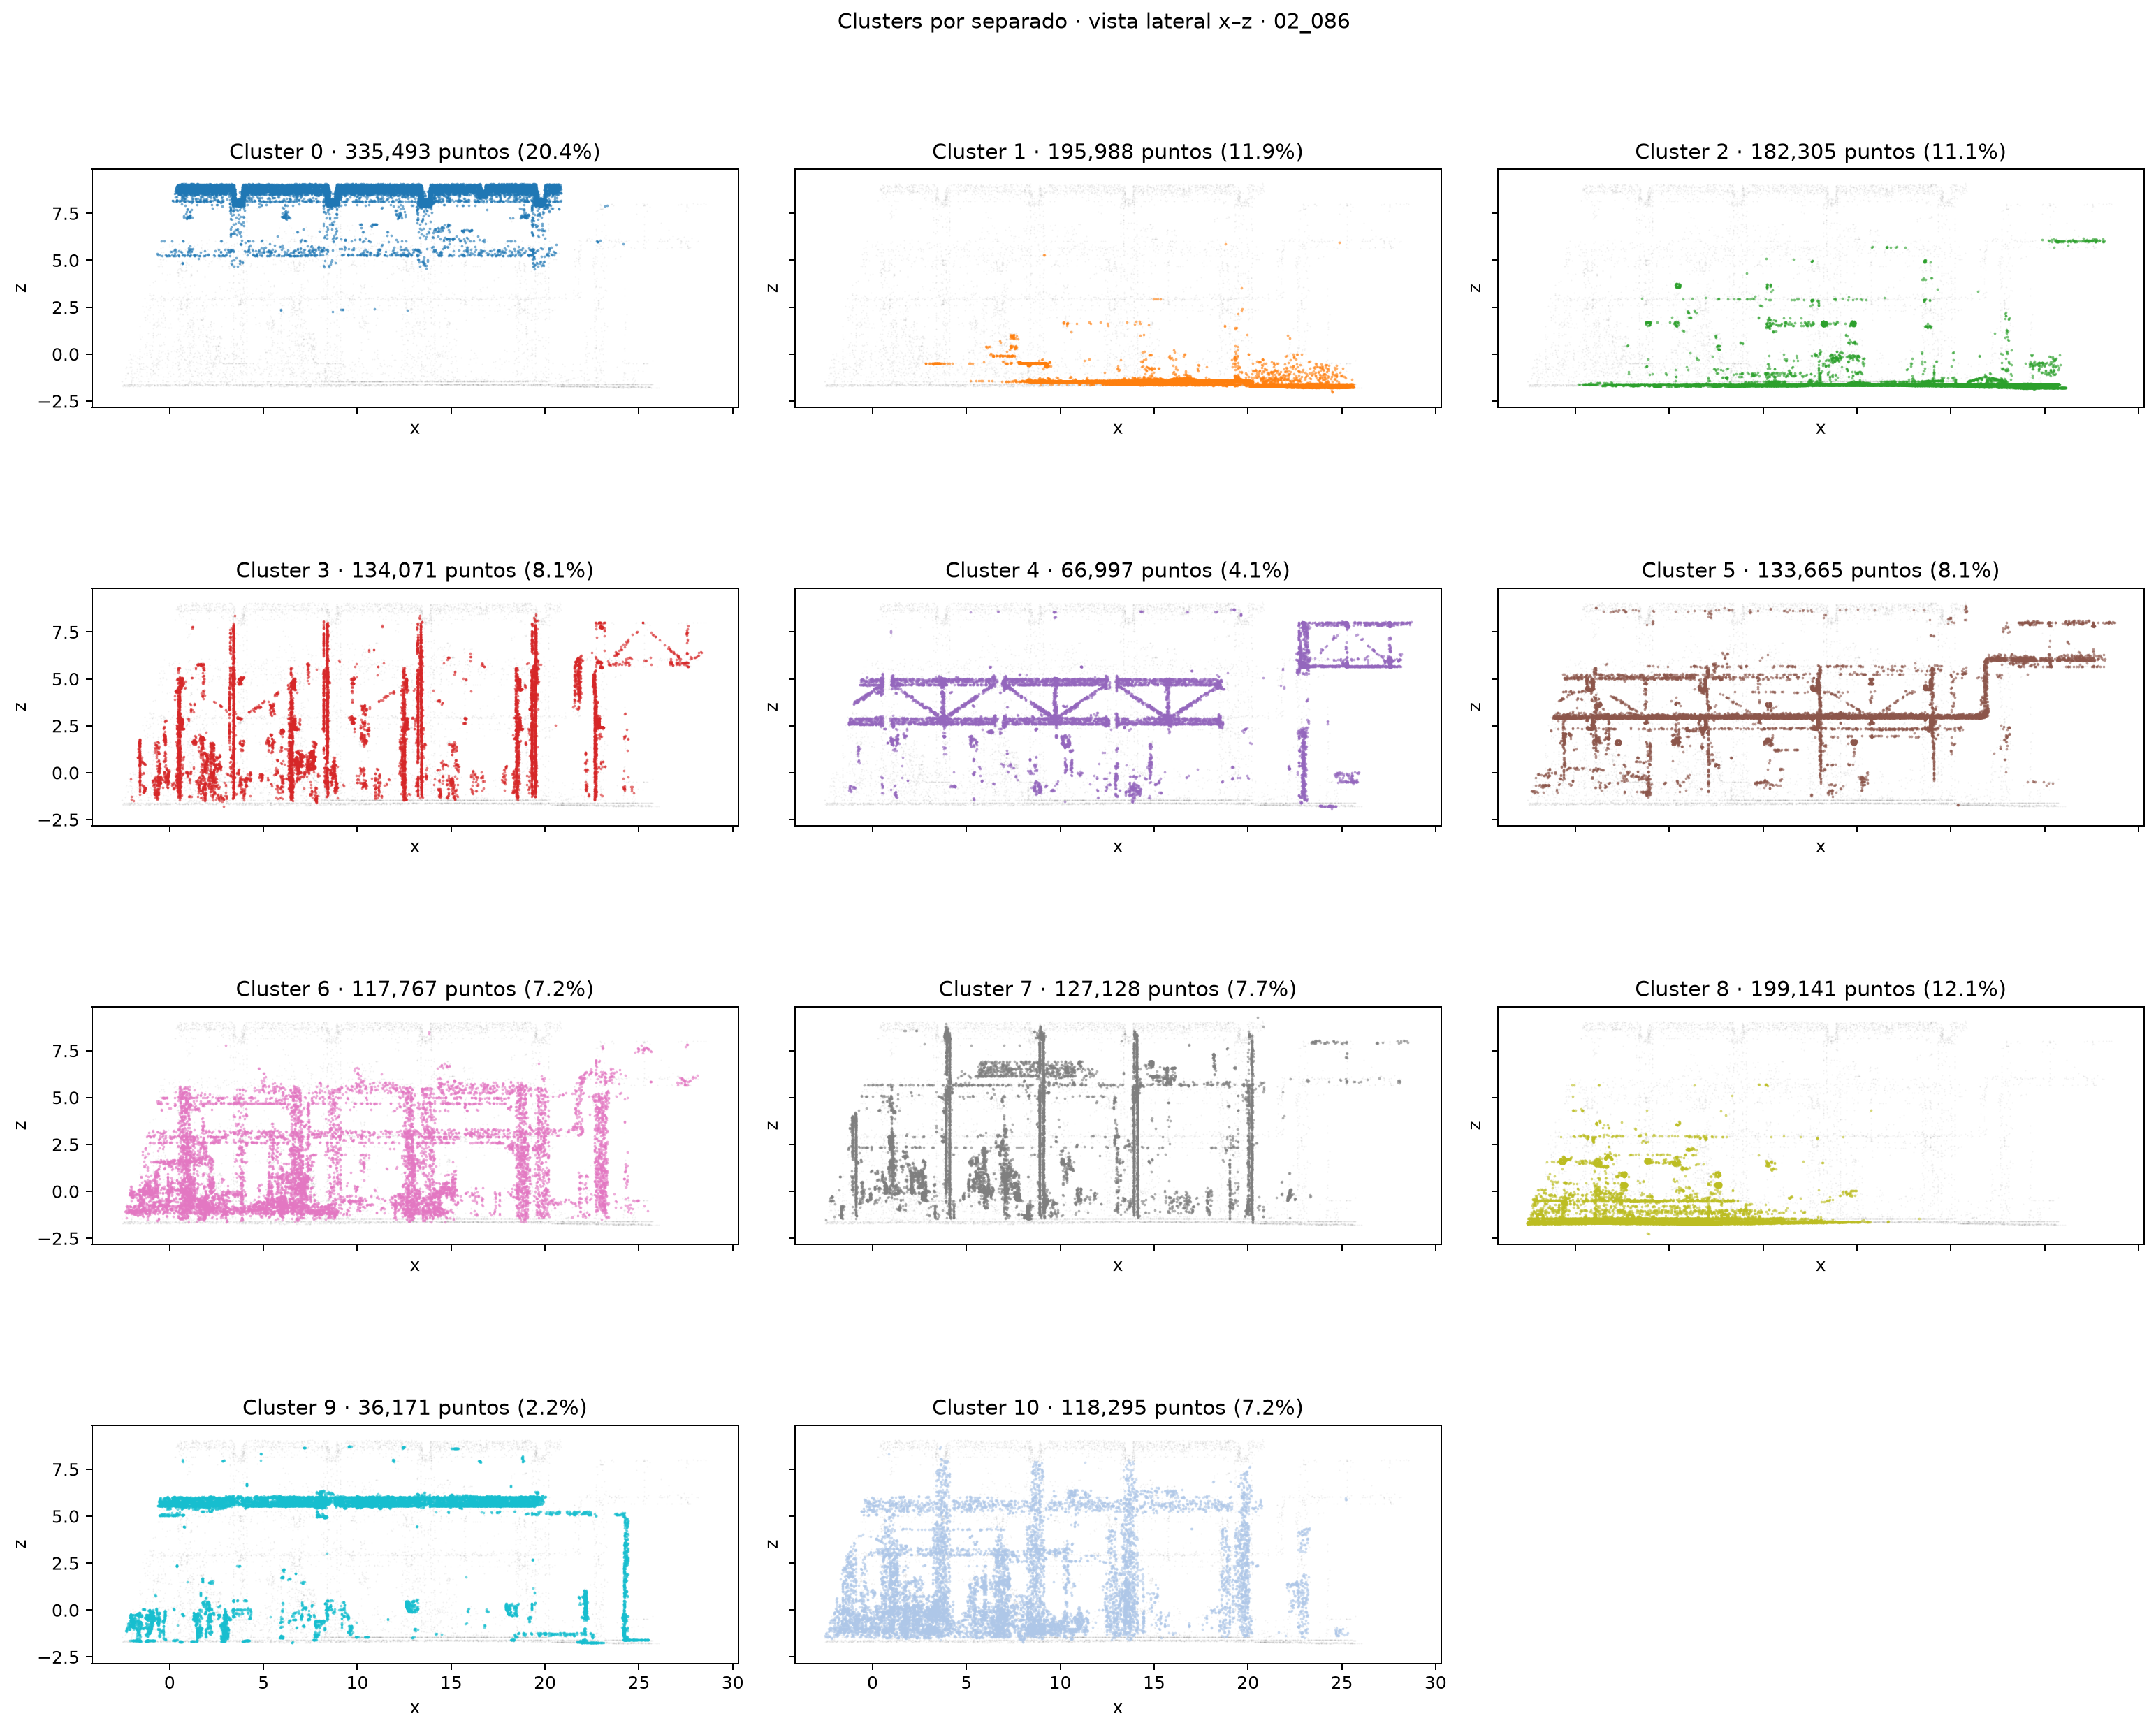

{'mejor': {'id': '02_086', 'metodo': 'kmeans', 'features': 'xyz+rgb+normales+height', 'estandarizado': True, 'parametros': '{"max_iter": 200, "n_clusters": 11, "n_init": 3}', 'n_fit': 93903, 'n_evaluacion': 93903, 'n_clusters': 11, 'ruido': 0.0, 'silhouette': 0.21325909321687836, 'DB': 1.5103333437568098, 'ARI': 0.9524523923670819, 'ARI_std': 0.03231755783193138, 'silhouette_comun': 0.21325909321687836, 'DB_comun': 1.5103333437568098, 'segundos': 0.8368715670003439, 'min_cluster_frac': 0.02298116141124352, 'max_cluster_frac': 0.18848173114809963, 'WCSS': 402965.6273301565, 'eps_propuesto': nan, 'vecinos_medios': nan, 'n_ajuste': nan, 'silhouette_ajuste': nan, 'DB_ajuste': nan, 'BIC': nan, 'converged': nan, 'seleccionado_bic': nan, 'elegible_estricto': True, 'elegible': True, 'etapa_seleccion': 'estricto', 'limite_max_cluster_frac': 0.6, 'limite_ruido': 0.3, 'rank_medio': 8.333333333333334}, 'configuraciones': 128, 'elegibles': 68, 'etapa_seleccion': 'estricto', 'pasos_seleccion': [{'et

In [12]:
ncols = 3; nrows = int(np.ceil(len(cluster_ids)/ncols))
fig, axes = plt.subplots(nrows,ncols,figsize=(17,3.5*nrows),squeeze=False,sharex=True,sharey=True)
rng = np.random.default_rng(0)
context_idx = rng.choice(len(labels_all),10000,replace=False)
context = cloud['xyz'][context_idx]
for ax,label in zip(axes.flat,cluster_ids):
    idx = np.flatnonzero(labels_all==label)
    size = len(idx)
    if len(idx)>12000: idx = rng.choice(idx,12000,replace=False)
    pts = cloud['xyz'][idx]
    color = segment_rgb(np.array([label]))[0]/255.
    ax.scatter(context[:,0],context[:,2],c='gray',s=.5,alpha=.10,linewidths=0)
    ax.scatter(pts[:,0],pts[:,2],color=color,s=2.2,alpha=.6,linewidths=0)
    ax.set(title=f'Cluster {label} · {size:,} puntos ({size/len(labels_all):.1%})',
           xlabel='x',ylabel='z',aspect='equal')
for ax in list(axes.flat)[len(cluster_ids):]: ax.set_visible(False)
fig.suptitle(f'Clusters por separado · vista lateral x–z · {best.id}',y=1.002)
fig.tight_layout(); fig.savefig(FIG/'06_clusters_separados.png',dpi=180,bbox_inches='tight'); display(Image(filename=str(FIG / '06_clusters_separados.png'))); plt.close(fig)
finish({'mejor':best.to_dict(),'configuraciones':len(results),'elegibles':len(eligible),
        'etapa_seleccion':selection_stage,'pasos_seleccion':selection_steps,
        'referencia_k2':k2.to_dict(),'seleccion_anterior_k2':previous.to_dict(),
        'refit_ari':refit_ari,'refit_seconds':refit_seconds,'propagate_seconds':propagate_seconds,
        'n_colores':color_count,'clusters':cluster_rows,
        'full_summary':cluster_summary(labels_all),'sample_summary':cluster_summary(labels)})

## Qué aprendimos / qué falló

De 128 configuraciones, 68 cumplieron el filtro aplicado, en la etapa estricto. No hizo falta relajar los límites de 6–15 clusters, ruido ≤30% y cluster mayor ≤60%. El mejor silhouette común con K=2 fue 0.2615; la elección anterior complete K=2 tenía 0.2465. Esos números más altos no daban el detalle buscado: techo frente al resto es una separación demasiado gruesa. La regla de ranks eligió 02_086 (kmeans, xyz+rgb+normales+height, {"max_iter": 200, "n_clusters": 11, "n_init": 3}): silhouette común 0.213, DB común 1.510 y ARI 0.9525. El reajuste reprodujo las etiquetas con ARI=1.000. Al propagar quedaron 11 grupos y 0.0% de ruido en la nube completa. Verificamos por relectura los 1 647 021 puntos, su orden, sus coordenadas, los colores uchar y las normales. El resultado es una partición según las features y el criterio elegido; sin ground truth no podemos asegurar que cada grupo sea un objeto. El nuevo PLY tiene 11 colores distintos y su cluster mayor ocupa 20.4% de los puntos completos. Los paneles separados permiten revisar qué partes se mezclan: más colores no garantiza clases semánticas. La propagación espacial y las submuestras de ajuste pueden suavizar o desplazar fronteras.

Lectura tentativa de las figuras (los grupos pueden mezclar estructuras):

| Cluster | Puntos completos | Qué se observa |
|---|---:|---|
| 0 | 335,493 | Techo/cubierta principal en z≈8–9, con fragmentos de vigas altas y una franja cerca de z≈5. |
| 1 | 195,988 | Piso en x medio–alto, mayormente hacia y positivo, más bases y superficies bajas de equipos. |
| 2 | 182,305 | Piso principalmente hacia y negativo, con bases/superficies bajas y algunos fragmentos elevados. |
| 3 | 134,071 | Elementos verticales compatibles con columnas o tuberías, mezclados con partes de equipos bajos; no individualiza cada columna. |
| 4 | 66,997 | Armazones de vigas y diagonales en z≈3–5, más la estructura lateral alta de x≈23–29. |
| 5 | 133,665 | Caras horizontales de vigas o tramos alargados cerca de z≈3 y 5, y parte del sector lateral alto; no distingue tubo de viga. |
| 6 | 117,767 | Mezcla de equipos y bases bajos, partes verticales y franjas horizontales intermedias. |
| 7 | 127,128 | Varias columnas/elementos verticales, principalmente hacia y positivo, con piezas alrededor de z≈5–6. |
| 8 | 199,141 | Piso del sector de x bajo (izquierda) y superficies bajas de equipos. |
| 9 | 36,171 | Franja horizontal concentrada en z≈5–6 y un elemento vertical en x≈24, además de pequeños fragmentos bajos. |
| 10 | 118,295 | Partes bajas de equipos y otras superficies verticales, con tramos horizontales cerca de z≈3 y 5. |
